# 35 数理统计

> **模块**：统计推断 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy、matplotlib

## 1. 问题背景

参数估计与假设检验是统计推断的两条主线：前者估计总体参数及其区间，后者判断关于总体的命题是否成立。

## 2. 学习目标

- 会做点估计与区间估计
- 理解 t 检验的前提与 p 值含义
- 能用 `scipy.stats` 完成常见检验

## 3. 环境与数据

- 依赖：numpy、matplotlib
- 数据：无（内置示例）

## 4. 方法与实现

### 4.1 数理统计

#### 区间估计
#### 经验分布函数
经验分布函数: $F_n(x)=\frac{1}{n}S(x),\ -\infty<x<\infty$, 其中$S(x)$表示$X_1,X_2,\cdots,X_n$中不大于$x$的随机变量个数.
#### Q-Q图

C:\Users\yohoten\AppData\Local\Temp\ipykernel_6604\2713439.py:51: UserWarning: Glyph 26679 (\N{CJK UNIFIED IDEOGRAPH-6837}) missing from current font.
  plt.tight_layout()
C:\Users\yohoten\AppData\Local\Temp\ipykernel_6604\2713439.py:51: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from current font.
  plt.tight_layout()
C:\Users\yohoten\AppData\Local\Temp\ipykernel_6604\2713439.py:51: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from current font.
  plt.tight_layout()
C:\Users\yohoten\AppData\Local\Temp\ipykernel_6604\2713439.py:51: UserWarning: Glyph 20301 (\N{CJK UNIFIED IDEOGRAPH-4F4D}) missing from current font.
  plt.tight_layout()
C:\Users\yohoten\AppData\Local\Temp\ipykernel_6604\2713439.py:51: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from current font.
  plt.tight_layout()
C:\Users\yohoten\AppData\Local\Temp\ipykernel_6604\2713439.py:51: UserWarning: Glyph 29702 (\N{CJK UNIFIED IDEOGRAPH-7406}) missing from cur

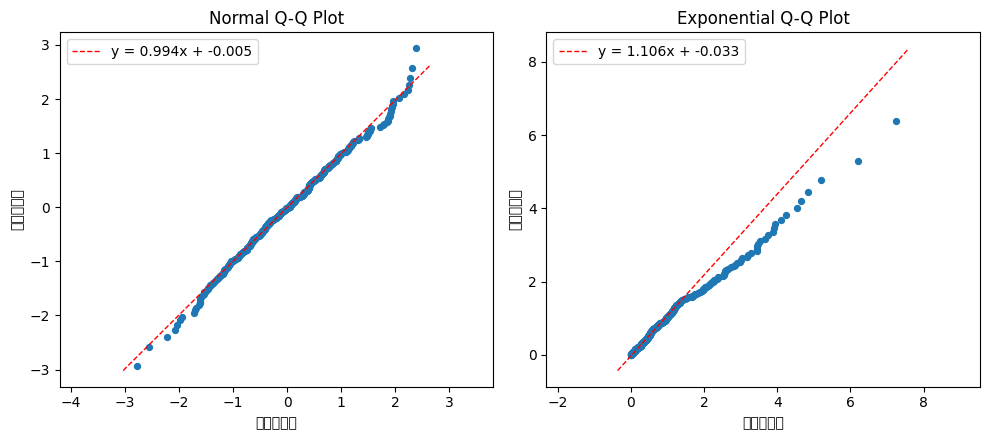

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


def QQplot(x, F_inv, ax=None, s=18, c="C0", label=None):
    """
    QQ 图：横轴 = 样本分位数，纵轴 = 理论分位数
    x     : 样本数据 (1D array-like)
    F_inv : 分布的分位函数（如 norm.ppf），需支持对 ndarray 逐元素运算
    """
    x = np.sort(np.asarray(x, dtype=float))
    n = x.size
    p = (np.arange(1, n + 1) - 0.5) / n          # 位置参数 (i-0.5)/n
    y = np.asarray(F_inv(p), dtype=float)        # 若 F_inv 不支持向量化，见下方说明

    if ax is None:
        ax = plt.gca()
    ax.scatter(x, y, s=s, c=c, label=label)

    # 参考线：通过第一、第三四分位数
    qx = np.percentile(x, [25, 75])
    qy = np.asarray(F_inv(np.array([0.25, 0.75])), dtype=float)
    slope = (qy[1] - qy[0]) / (qx[1] - qx[0])
    intercept = qy[0] - slope * qx[0]
    xs = np.array(ax.get_xlim())
    ax.plot(xs, slope * xs + intercept, "r--", lw=1,
            label=f"y = {slope:.3f}x + {intercept:.3f}")

    ax.set_xlabel("样本分位数")
    ax.set_ylabel("理论分位数")
    ax.legend()
    ax.set_aspect("equal", adjustable="datalim")  # QQ 图通常用等比例坐标
    return ax

np.random.seed(0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# 正态样本
data_n = np.random.randn(300)
QQplot(data_n, norm.ppf, ax=axes[0])
axes[0].set_title("Normal Q-Q Plot")

# 指数样本（用指数分布的分位函数）
from scipy.stats import expon
data_e = np.random.exponential(scale=1.0, size=300)
QQplot(data_e, expon.ppf, ax=axes[1])
axes[1].set_title("Exponential Q-Q Plot")

plt.tight_layout()
plt.show()

## 5. 小结

检验结论依赖显著性水平与前提假设；报告应同时给出统计量、p 值与置信区间，而不是只写“显著”。

> 内容来源：教材参考实现《数学建模算法与应用》练习稿（MIT，Zhanghan Wang），原始文件已并入本篇，见 `THIRD-PARTY.md`。